In [1]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import torch

In [2]:
DATASET_DIR = Path("data")

train_dir = DATASET_DIR / "train"
valid_dir = DATASET_DIR / "valid"
test_dir = DATASET_DIR / "test"

egg_images = list(train_dir.joinpath("egg").glob("*.jpg"))

print("Training images:", len(egg_images))
print("First image:", egg_images[0])

Training images: 75
First image: data/train/egg/not_damaged_100_jpg.rf.5d780a6024004fa2f68741fa56ddf4c9.jpg


In [3]:
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


### loading  the model 
we are using SAM ViT-B , due to lightweight and suitable for over hard wear 

In [4]:
from transformers import SamModel, SamProcessor

MODEL_NAME = "facebook/sam-vit-base"

processor = SamProcessor.from_pretrained(MODEL_NAME)
model = SamModel.from_pretrained(MODEL_NAME)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)

print("Model loaded on:", device)

/home/mohsinkhan/Egg/venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 314/314 [00:00<00:00, 1187.74it/s]


Model loaded on: cuda


In [5]:
image_path = egg_images[0]

image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

inputs = processor(images=image, return_tensors="pt")

print("Input pixel values shape:", inputs["pixel_values"].shape)

Input pixel values shape: torch.Size([1, 3, 1024, 1024])


### Generate a mask using SAM

point the center of egg to, let SAm know whihc object need to detect/ segment 

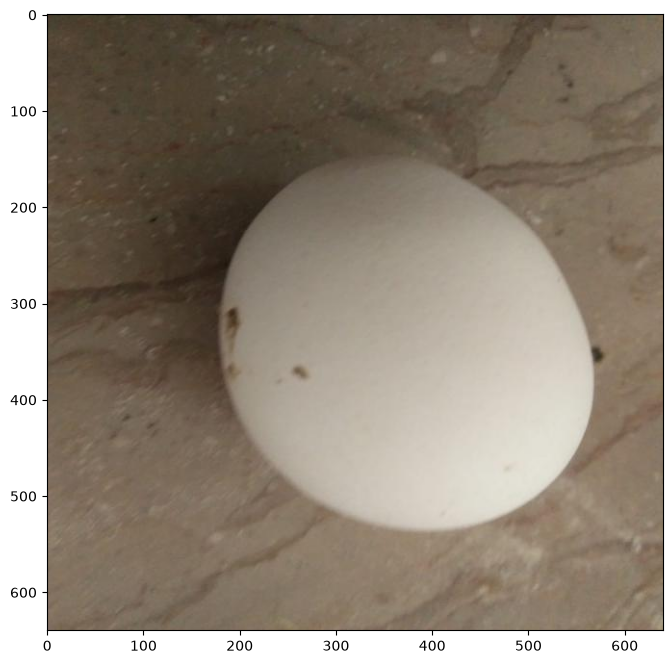

In [6]:
plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.axis("on")
plt.show()

In [7]:
point_coords = [[[400, 350]]]
point_labels = [[1]]

inputs = processor(
    images=image,
    input_points=point_coords,
    input_labels=point_labels,
    return_tensors="pt"
)

inputs = {key: value.to(device) for key, value in inputs.items()}

print("Point prompt:", point_coords)

Point prompt: [[[400, 350]]]


In [8]:
with torch.no_grad():
    outputs = model(**inputs)

print("Predicted masks shape:", outputs.pred_masks.shape)
print("Predicted IoU scores shape:", outputs.iou_scores.shape)

Predicted masks shape: torch.Size([1, 1, 3, 256, 256])
Predicted IoU scores shape: torch.Size([1, 1, 3])


In [9]:
masks = outputs.pred_masks[0, 0]
scores = outputs.iou_scores[0, 0]

best_idx = scores.argmax().item()
best_mask = masks[best_idx]

print("IoU scores:", scores.cpu().numpy())
print("Best mask index:", best_idx)
print("Best mask shape:", best_mask.shape)

IoU scores: [0.9577706 1.0135049 0.9732715]
Best mask index: 1
Best mask shape: torch.Size([256, 256])


### Display the selected mask

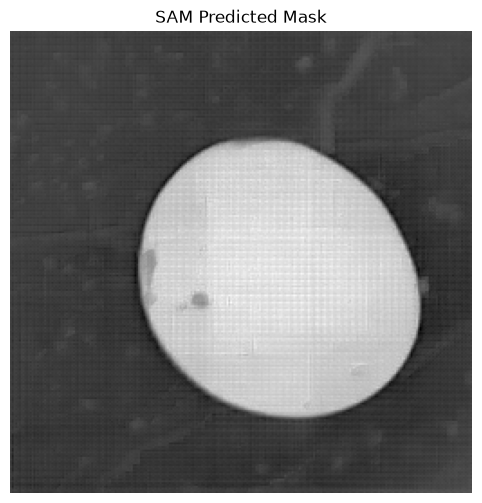

In [10]:
mask = best_mask.cpu().numpy()

plt.figure(figsize=(6, 6))
plt.imshow(mask, cmap="gray")
plt.title("SAM Predicted Mask")
plt.axis("off");

### Convert the mask to binary
for taking clear look of mask 
we going to use threshold for that

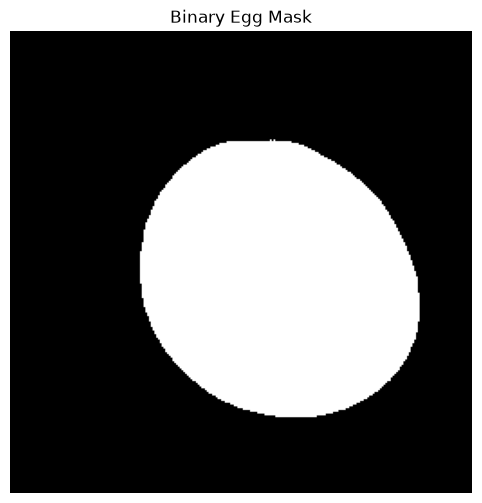

In [11]:
binary_mask = mask > 0

plt.figure(figsize=(6, 6))
plt.imshow(binary_mask, cmap="gray")
plt.title("Binary Egg Mask")
plt.axis("off");

### Put the mask on original image 
this is to find whether to prediction is aligns with egg boundary

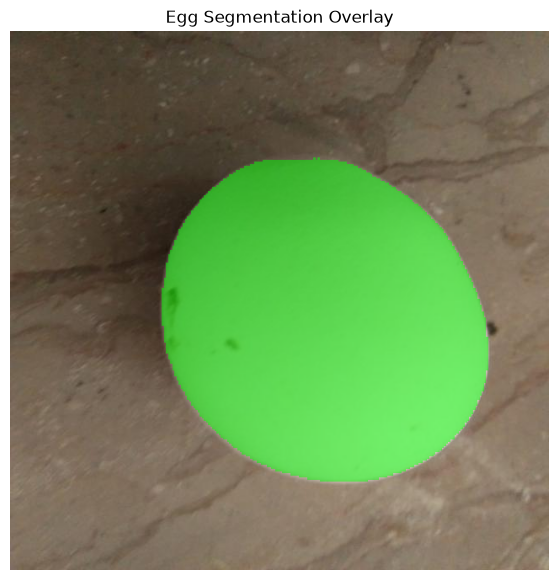

In [12]:
import numpy as np

resized_mask = cv2.resize(
    binary_mask.astype(np.uint8),
    (image.shape[1], image.shape[0]),
    interpolation=cv2.INTER_NEAREST
)

overlay = image.copy()
overlay[resized_mask == 1] = (
    0.5 * overlay[resized_mask == 1] + 0.5 * np.array([0, 255, 0])
).astype(np.uint8)

plt.figure(figsize=(7, 7))
plt.imshow(overlay)
plt.title("Egg Segmentation Overlay")
plt.axis("off");

### Test on image that containing multiple eggs 
i am going to manualy select an image from data set which is best fit for that test

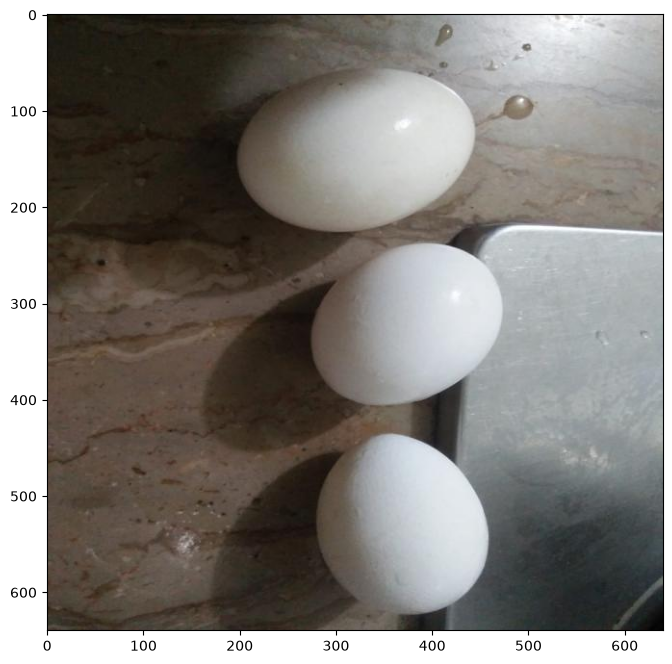

In [16]:
multi_egg_path = train_dir / "egg" / "not_damaged_103_jpg.rf.c0bd961caec5acf3a6582c9cb2551634.jpg"

image_multi = cv2.imread(str(multi_egg_path))
image_multi = cv2.cvtColor(image_multi, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 8))
plt.imshow(image_multi)
plt.axis("on");

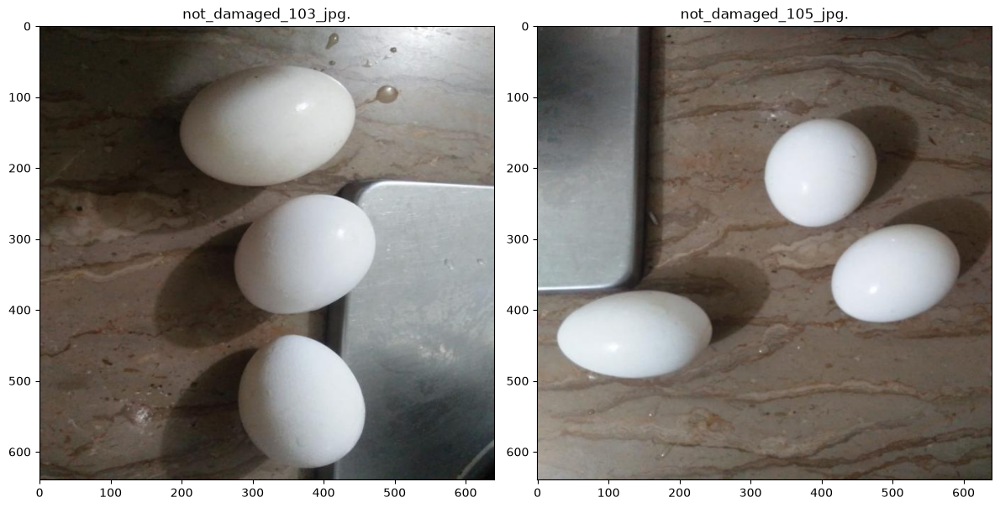

In [17]:
image_paths = [
    train_dir / "egg" / "not_damaged_103_jpg.rf.c0bd961caec5acf3a6582c9cb2551634.jpg",
    train_dir / "egg" / "not_damaged_105_jpg.rf.6b94b57d4e4cb521abbec55bb95c2a76.jpg"
]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, path in zip(axes, image_paths):
    img = cv2.imread(str(path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(path.name[:20])
    ax.axis("on")

plt.tight_layout()

In [18]:
point_coords = [[
    [300, 130],  # Top egg
    [350, 330],  # Middle egg
    [370, 530]   # Bottom egg
]]

point_labels = [[1, 1, 1]]

inputs_multi = processor(
    images=image_multi,
    input_points=point_coords,
    input_labels=point_labels,
    return_tensors="pt"
)

inputs_multi = {
    key: value.to(device)
    for key, value in inputs_multi.items()
}

print("Input points:", point_coords)

Input points: [[[300, 130], [350, 330], [370, 530]]]


In [19]:
with torch.no_grad():
    outputs_multi = model(**inputs_multi)

print("Predicted masks shape:", outputs_multi.pred_masks.shape)
print("IoU scores shape:", outputs_multi.iou_scores.shape)

Predicted masks shape: torch.Size([1, 1, 3, 256, 256])
IoU scores shape: torch.Size([1, 1, 3])


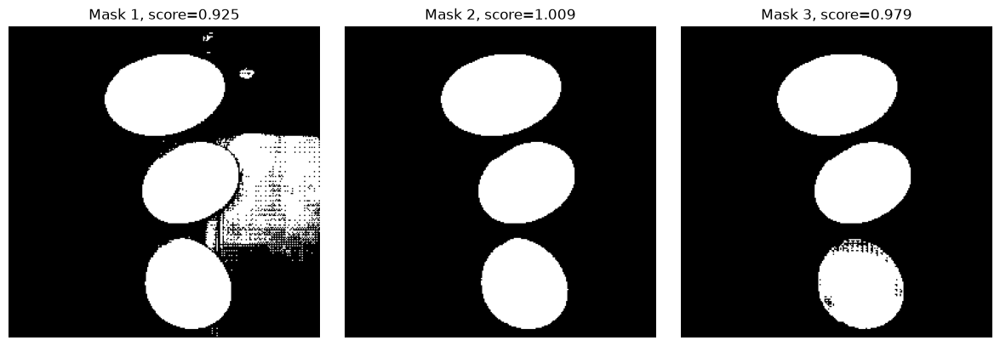

In [20]:
masks_multi = outputs_multi.pred_masks[0, 0].cpu().numpy()
scores_multi = outputs_multi.iou_scores[0, 0].cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for i, ax in enumerate(axes):
    ax.imshow(masks_multi[i] > 0, cmap="gray")
    ax.set_title(f"Mask {i + 1}, score={scores_multi[i]:.3f}")
    ax.axis("off")

plt.tight_layout()

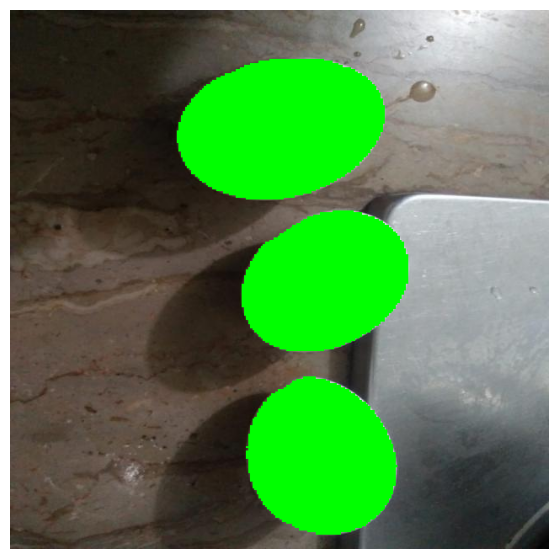

In [21]:
mask = masks_multi[1] > 0

resized_mask = cv2.resize(
    mask.astype("uint8"),
    (image_multi.shape[1], image_multi.shape[0]),
    interpolation=cv2.INTER_NEAREST
)

overlay = image_multi.copy()
overlay[resized_mask == 1] = [0, 255, 0]

plt.figure(figsize=(7, 7))
plt.imshow(overlay)
plt.axis("off");

area covered by mask 

In [22]:
egg_pixels = np.count_nonzero(resized_mask)
total_pixels = resized_mask.size

print("Egg pixels:", egg_pixels)
print("Total pixels:", total_pixels)
print("Egg area (%):", round(egg_pixels / total_pixels * 100, 2))

Egg pixels: 83342
Total pixels: 409600
Egg area (%): 20.35


We are able to segment the egg image and create mask for egg image but problem it we are still entering the center of egg manually -> we need to automate it we have some approches to deal with this. 
1. SAM Automatic mask generator 
2. Object detection +SAM
3. Automatic point selection and SAM-> use image processing technique 

## Method 1: SAM Automatic Mask Generator

we'll first check whether the required library is available

In [23]:
try:
    from segment_anything import SamAutomaticMaskGenerator
    print("SAM automatic mask generator is available.")
except ImportError:
    print("SAM automatic mask generator is not installed.")

SAM automatic mask generator is available.


In [25]:
from pathlib import Path

list(Path(".").glob("**/*.pth"))

[PosixPath('venv/lib/python3.14/site-packages/distutils-precedence.pth')]

the automatic mask generator needs Meta's original model interface.

In [26]:
%pip install git+https://github.com/facebookresearch/segment-anything.git

  Cloning https://github.com/facebookresearch/segment-anything.git to /tmp/pip-req-build-wqanmzkl
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/segment-anything.git /tmp/pip-req-build-wqanmzkl
  Resolved https://github.com/facebookresearch/segment-anything.git to commit dca509fe793f601edb92606367a655c15ac00fdf
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [37]:
from pathlib import Path
import urllib.request

checkpoint_dir = Path("models")
checkpoint_dir.mkdir(exist_ok=True)

checkpoint_path = checkpoint_dir / "sam_vit_b_01ec64.pth"

if not checkpoint_path.exists():
    url = (
        "https://dl.fbaipublicfiles.com/segment_anything/"
        "sam_vit_b_01ec64.pth"
    )
    urllib.request.urlretrieve(url, checkpoint_path)

print(f"Checkpoint saved: {checkpoint_path}")
print(f"Size: {checkpoint_path.stat().st_size / (1024**3):.2f} GB")

Checkpoint saved: models/sam_vit_b_01ec64.pth
Size: 0.35 GB


In [38]:
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator

checkpoint_path = "models/sam_vit_b_01ec64.pth"

sam = sam_model_registry["vit_b"](checkpoint=checkpoint_path)
sam.to(device=device)

mask_generator = SamAutomaticMaskGenerator(sam)

print("SAM Automatic Mask Generator initialized!")

SAM Automatic Mask Generator initialized!


In [39]:
import gc
import torch

# Move Meta's SAM to CPU
sam.to("cpu")

# Move Hugging Face SAM to CPU if it still exists
if "model" in globals():
    model.to("cpu")

gc.collect()
torch.cuda.empty_cache()

print("Models moved to CPU.")
print("GPU memory allocated:", round(
    torch.cuda.memory_allocated() / 1024**3, 2
), "GB")

Models moved to CPU.
GPU memory allocated: 1.22 GB


In [40]:
import gc
import torch

if "model" in globals():
    model.cpu()
    del model

if "outputs" in globals():
    del outputs

if "outputs_multi" in globals():
    del outputs_multi

gc.collect()
torch.cuda.empty_cache()

print(torch.cuda.memory_summary())

|===========================================================================|
|                  PyTorch CUDA memory summary, device ID 0                 |
|---------------------------------------------------------------------------|
|            CUDA OOMs: 3            |        cudaMalloc retries: 3         |
|===========================================================================|
|        Metric         | Cur Usage  | Peak Usage | Tot Alloc  | Tot Freed  |
|---------------------------------------------------------------------------|
| Allocated memory      |   1252 MiB |   3249 MiB |  34181 MiB |  32929 MiB |
|       from large pool |   1240 MiB |   3226 MiB |  33902 MiB |  32661 MiB |
|       from small pool |     12 MiB |     32 MiB |    279 MiB |    267 MiB |
|---------------------------------------------------------------------------|
| Active memory         |   1252 MiB |   3249 MiB |  34181 MiB |  32929 MiB |
|       from large pool |   1240 MiB |   3226 MiB |  33902 MiB |

In [41]:
import time
import cv2
import matplotlib.pyplot as plt

image_path = (
    train_dir / "egg" /
    "not_damaged_103_jpg.rf.c0bd961caec5acf3a6582c9cb2551634.jpg"
)

image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

start_time = time.perf_counter()
masks = mask_generator.generate(image)
elapsed_time = time.perf_counter() - start_time

print(f"Image shape: {image.shape}")
print(f"Number of masks generated: {len(masks)}")
print(f"Inference time: {elapsed_time:.2f} seconds")

Image shape: (640, 640, 3)
Number of masks generated: 29
Inference time: 75.89 seconds


In [42]:
!nvidia-smi

Thu Oct 29 23:50:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 615.71.09              KMD Version: 615.71.09     CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050 ...    Off |   00000000:01:00.0 Off |                  N/A |
| N/A   63C    P8              3W /   60W |    1907MiB /   4096MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [43]:
import time

start_time = time.perf_counter()
masks = mask_generator.generate(image)
elapsed_time = time.perf_counter() - start_time

print("Masks generated:", len(masks))
print(f"Inference time: {elapsed_time:.2f} seconds")

Masks generated: 29
Inference time: 78.83 seconds


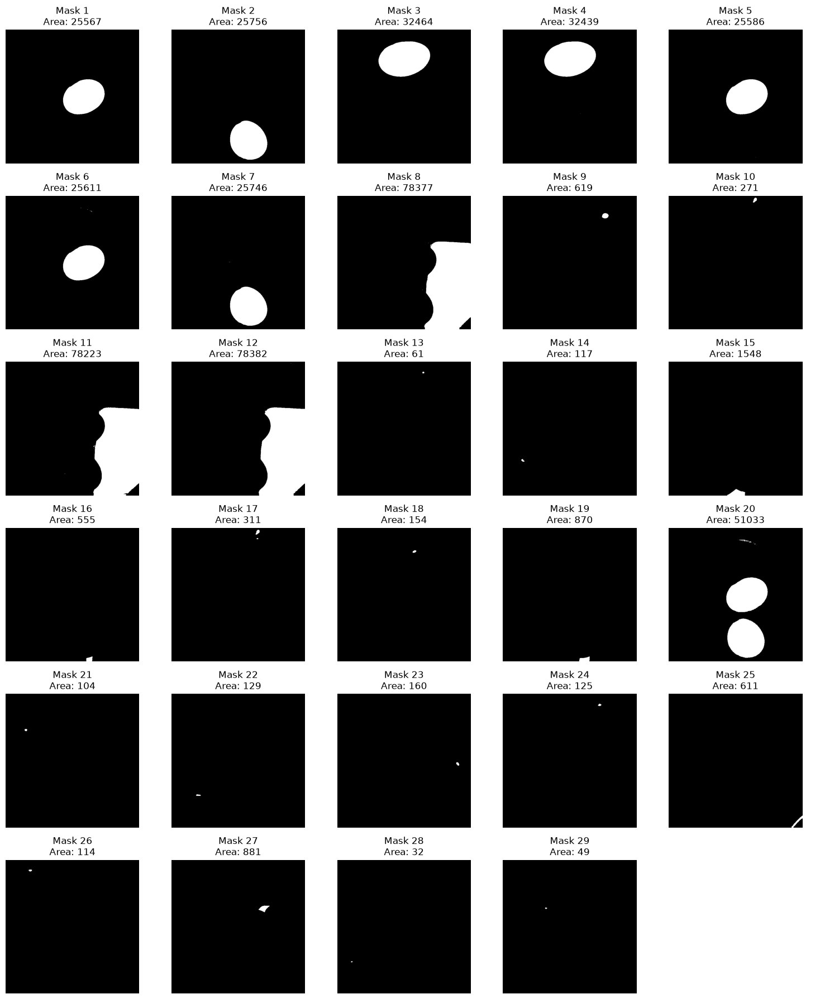

In [44]:
import matplotlib.pyplot as plt
import math

cols = 5
rows = math.ceil(len(masks) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3))
axes = axes.flatten()

for i, mask_data in enumerate(masks):
    axes[i].imshow(mask_data["segmentation"], cmap="gray")
    axes[i].set_title(
        f"Mask {i + 1}\n"
        f"Area: {mask_data['area']}"
    )
    axes[i].axis("off")

for i in range(len(masks), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

We will not continue with standalone SAM Automatic Mask Generation as our primary segmentation pipeline.

The main issues are its high inference time, inconsistent candidate masks, and the difficulty of identifying egg masks automatically. Although additional filtering could improve the results, that would introduce another stage without guaranteeing reliable egg segmentation.

Important limitation: We evaluated a small number of images, so this experiment does not prove that SAM Automatic Mask Generation is unsuitable for every egg image. It indicates that the method, in its current configuration, is not a practical fit for our project.



## Method 2: Automatic Point Selection + SAM
improve SAM by automatically finding likely egg centers and using them as positive prompts.

Select an image and inspect its color channels.We need to determine whether image processing can locate the eggs using brightness, color, or contras

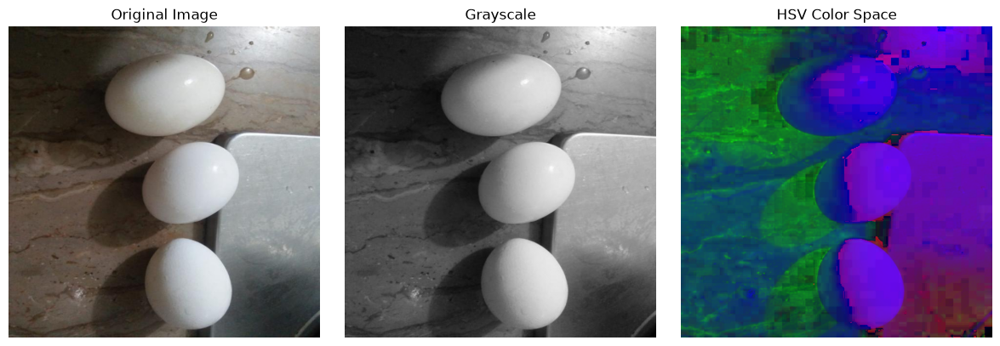

In [45]:
import cv2
import matplotlib.pyplot as plt

image_bgr = cv2.imread(str(image_path))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV))
plt.title("HSV Color Space")
plt.axis("off")

plt.tight_layout()
plt.show()

**Detect candidate egg regions**: 
Let's use Otsu's thresholding to separate bright pixels from darker pixels, then inspect the result before using it to generate SAM points.

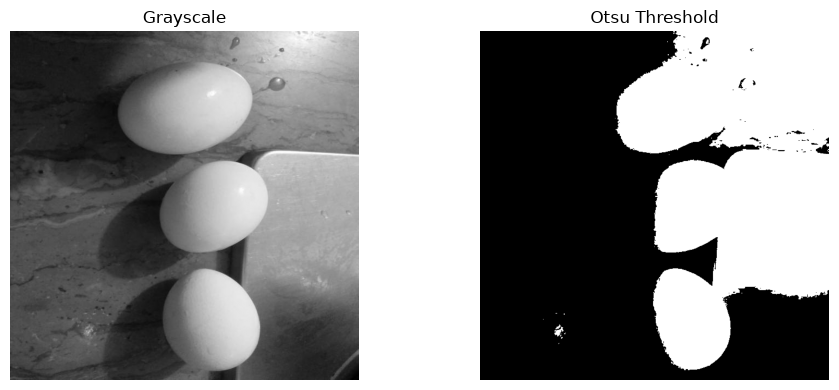

In [46]:
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

_, binary = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap="gray")
plt.title("Otsu Threshold")
plt.axis("off")

plt.tight_layout()
plt.show()

In [47]:
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    binary,
    connectivity=8
)

print("Number of foreground regions:", num_labels - 1)

for i in range(1, num_labels):
    x, y, w, h, area = stats[i]
    cx, cy = centroids[i]

    print(
        f"Region {i}: area={area}, "
        f"width={w}, height={h}, "
        f"center=({cx:.1f}, {cy:.1f})"
    )

Number of foreground regions: 31
Region 1: area=9, width=3, height=5, center=(354.9, 1.8)
Region 2: area=164138, width=392, height=622, center=(468.7, 263.5)
Region 3: area=2, width=1, height=2, center=(343.0, 18.5)
Region 4: area=4, width=2, height=2, center=(344.5, 42.5)
Region 5: area=1, width=1, height=1, center=(304.0, 75.0)
Region 6: area=1, width=1, height=1, center=(477.0, 101.0)
Region 7: area=1, width=1, height=1, center=(247.0, 159.0)
Region 8: area=1, width=1, height=1, center=(434.0, 189.0)
Region 9: area=2, width=1, height=2, center=(424.0, 195.5)
Region 10: area=1, width=1, height=1, center=(626.0, 215.0)
Region 11: area=9, width=3, height=6, center=(638.2, 218.2)
Region 12: area=1, width=1, height=1, center=(346.0, 226.0)
Region 13: area=1, width=1, height=1, center=(319.0, 395.0)
Region 14: area=2, width=2, height=1, center=(479.5, 480.0)
Region 15: area=7, width=3, height=3, center=(630.3, 482.0)
Region 16: area=1, width=1, height=1, center=(555.0, 487.0)
Region 17: a

the three eggs are connected to the bright background, so OpenCV detects one huge region instead of three separate eggs

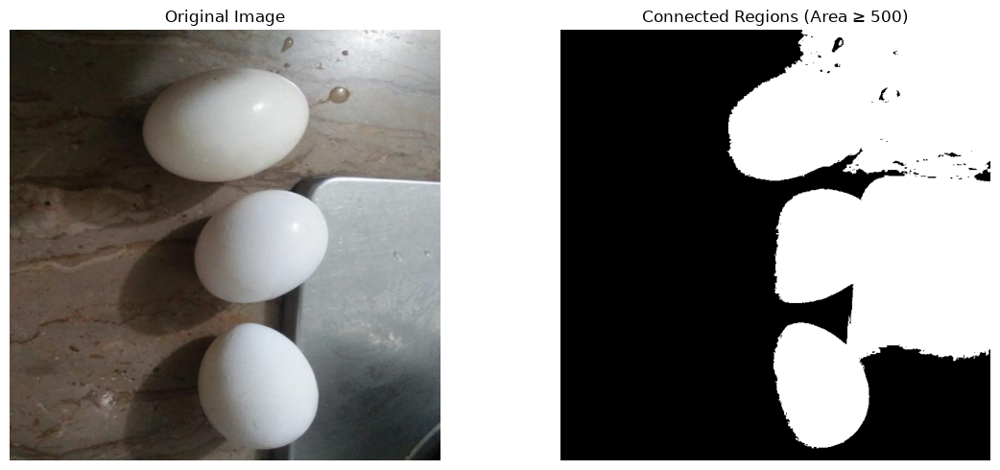

In [48]:
import numpy as np
import matplotlib.pyplot as plt

min_area = 500

candidate_mask = np.zeros_like(binary)

for i in range(1, num_labels):
    area = stats[i, cv2.CC_STAT_AREA]

    if area >= min_area:
        candidate_mask[labels == i] = 255

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(candidate_mask, cmap="gray")
plt.title("Connected Regions (Area ≥ 500)")
plt.axis("off")

plt.tight_layout()
plt.show()

Otsu thresholding identifies bright regions, not eggs specifically.
The bright background merges with the eggs.
Connected-component analysis therefore detects one large region instead of three individual eggs.
Using that region's centroid would not give us reliable egg centers.

## Method 2B: Local peak detection using image processing,

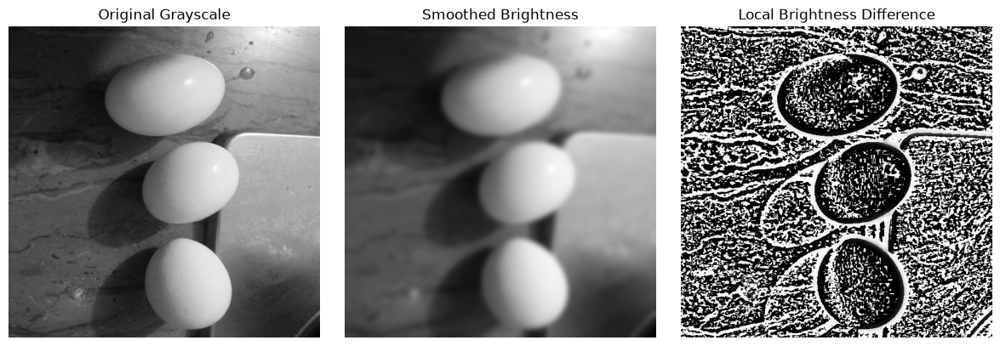

In [49]:
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

# Smooth the image to reduce small variations
blurred = cv2.GaussianBlur(gray, (31, 31), 0)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(blurred, cmap="gray")
plt.title("Smoothed Brightness")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gray - blurred, cmap="gray")
plt.title("Local Brightness Difference")
plt.axis("off")

plt.tight_layout()
plt.show()

find local brightness maxima inside each egg

Candidate center points: 833


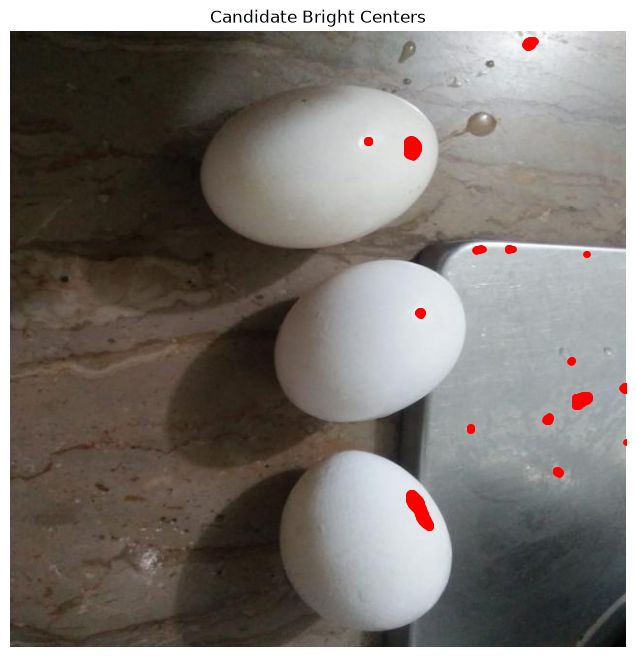

In [50]:
import numpy as np
from scipy.ndimage import maximum_filter

# Find local brightness maxima in the smoothed image
local_max = maximum_filter(blurred, size=51)

# Keep pixels that are local maxima and sufficiently bright
threshold = 150
peaks = (blurred == local_max) & (blurred > threshold)

ys, xs = np.where(peaks)

print("Candidate center points:", len(xs))

plt.figure(figsize=(8, 8))
plt.imshow(image_rgb)
plt.scatter(xs, ys, s=15, c="red")
plt.title("Candidate Bright Centers")
plt.axis("off")
plt.show()

too much loacl maxima -> difficult to find a center of egg. we need to try another method. 


let's use the image's edges to identify egg-shaped regions,

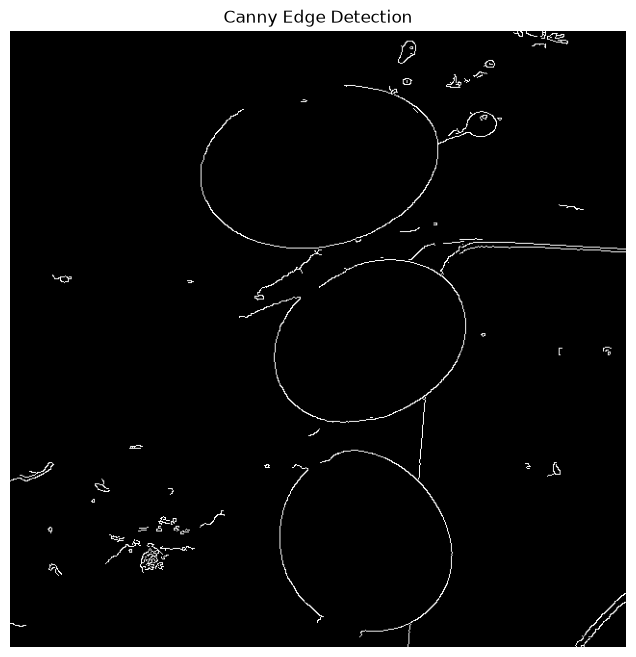

In [51]:
edges = cv2.Canny(gray, 50, 150)

plt.figure(figsize=(8, 8))
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")
plt.show()

In [52]:
# Smooth the grayscale image to reduce texture
blurred_edges = cv2.GaussianBlur(gray, (7, 7), 0)

# Detect contours from the smoothed image
edges = cv2.Canny(blurred_edges, 30, 100)

# Connect small gaps in egg boundaries
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
edges_closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel)

contours, _ = cv2.findContours(
    edges_closed,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

print("Contours found:", len(contours))

Contours found: 20


I think we should stop experimenting with classical image-processing techniques for now and return to the main objective: finding the best egg-segmentation method by comparing accuracy and inference time.

there is huge chance of imporoment, and many way to experiment, but we have better pre known methods that i have work with previusly like object detecion and segmentaion so we are going to continue with them ,

we have try this to just know they can work and there is way to improve this methods, next object detection and Sam combined , this method work for me in past 

### Object detector + SAM

In [53]:
import torch

print("Image shape:", image.shape)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(
        "GPU memory allocated:",
        round(torch.cuda.memory_allocated() / 1024**3, 2),
        "GB"
    )

Image shape: (640, 640, 3)
CUDA available: True
GPU memory allocated: 1.22 GB


In [54]:
try:
    from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
    print("Grounding DINO dependencies are available.")
except ImportError as e:
    print("Missing dependency:", e)

Grounding DINO dependencies are available.


In [55]:
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
import torch

MODEL_ID = "IDEA-Research/grounding-dino-tiny"

processor_dino = AutoProcessor.from_pretrained(MODEL_ID)
model_dino = AutoModelForZeroShotObjectDetection.from_pretrained(MODEL_ID)

print("Grounding DINO loaded on CPU.")

Loading weights: 100%|██████████| 978/978 [00:00<00:00, 12268.74it/s]

Grounding DINO loaded on CPU.


In [56]:
import time
import torch

inputs = processor_dino(
    images=image,
    text="egg.",
    return_tensors="pt"
)

start_time = time.perf_counter()

with torch.no_grad():
    outputs = model_dino(**inputs)

print(f"Inference time: {time.perf_counter() - start_time:.2f} seconds")

Inference time: 5.93 seconds


In [57]:
import inspect

print(inspect.signature(processor_dino.post_process_grounded_object_detection))

(outputs: 'GroundingDinoObjectDetectionOutput', input_ids: transformers.utils.generic.TensorType | None = None, threshold: float = 0.25, text_threshold: float = 0.25, target_sizes: transformers.utils.generic.TensorType | list[tuple] | None = None, text_labels: list[list[str]] | None = None)


Detected objects: 3
egg | Confidence: 0.812 | Box: [196.7  54.3 446.  227.2]
egg | Confidence: 0.790 | Box: [273.6 236.2 474.4 407.3]
egg | Confidence: 0.797 | Box: [279.2 434.  460.2 624.5]


/home/mohsinkhan/Egg/venv/lib64/python3.14/site-packages/transformers/models/grounding_dino/processing_grounding_dino.py:89: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


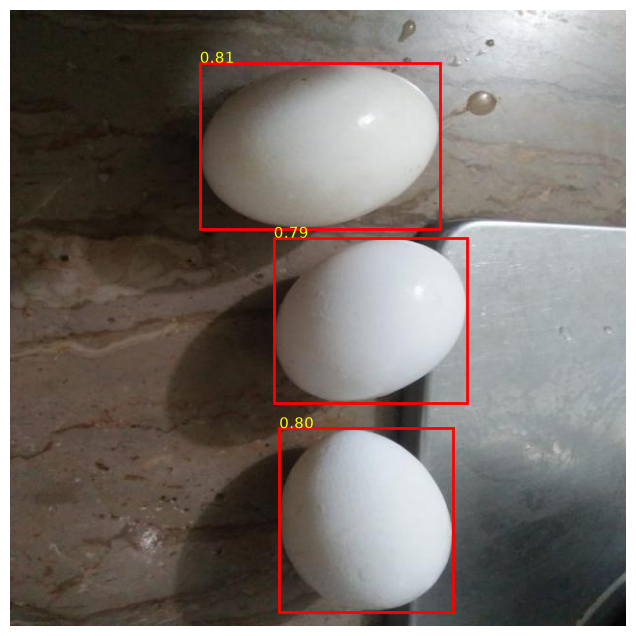

In [58]:
import matplotlib.pyplot as plt
from PIL import Image
import torch

results = processor_dino.post_process_grounded_object_detection(
    outputs,
    inputs.input_ids,
    threshold=0.25,
    text_threshold=0.25,
    target_sizes=[image.shape[:2]]
)[0]

boxes = results["boxes"].cpu().numpy()
scores = results["scores"].cpu().numpy()
labels = results["labels"]

print(f"Detected objects: {len(boxes)}")

for label, score, box in zip(labels, scores, boxes):
    print(f"{label} | Confidence: {score:.3f} | Box: {box.round(1)}")

plt.figure(figsize=(10, 8))
plt.imshow(image)

ax = plt.gca()
for box, score in zip(boxes, scores):
    x1, y1, x2, y2 = box
    rect = plt.Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        fill=False, edgecolor="red", linewidth=2
    )
    ax.add_patch(rect)
    ax.text(x1, y1, f"{score:.2f}", color="yellow", fontsize=11)

plt.axis("off")
plt.show()

In [59]:
from segment_anything import SamPredictor
import numpy as np
import time

predictor = SamPredictor(sam)
predictor.set_image(image)

print("SAM image embedding computed successfully.")

SAM image embedding computed successfully.


In [61]:
import time
import numpy as np

predictor.set_image(image)

start_time = time.perf_counter()
egg_masks = []

for box in boxes:
    masks, scores_sam, _ = predictor.predict(
        box=box.astype(np.float32),
        multimask_output=False
    )
    egg_masks.append(masks[0])

print("Eggs segmented:", len(egg_masks))
print(f"Segmentation time: {time.perf_counter() - start_time:.2f} seconds")

Eggs segmented: 3
Segmentation time: 0.19 seconds


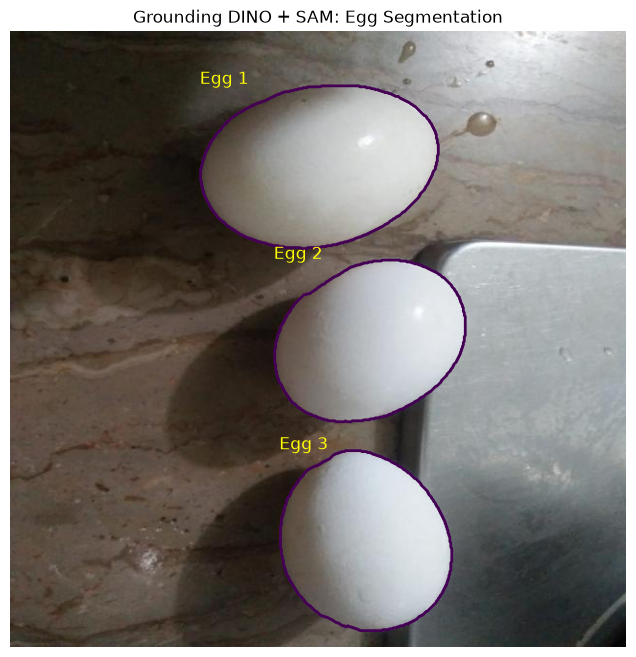

In [62]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 8))
plt.imshow(image)

ax = plt.gca()
for i, mask in enumerate(egg_masks):
    ax.contour(mask.astype(float), levels=[0.5], linewidths=2)
    x1, y1, _, _ = boxes[i]
    ax.text(x1, y1, f"Egg {i+1}", color="yellow", fontsize=12)

plt.title("Grounding DINO + SAM: Egg Segmentation")
plt.axis("off")
plt.show()

Test the pipeline on another image

In [63]:
image_path = "data/test/egg/not_damaged_105_jpg.rf.6b94b57d4e4cb521abbec55bb95c2a76.jpg"

In [65]:
test_dir = Path("data/test/egg")
print("Images found:", len(list(test_dir.glob("*"))))
print([p.name for p in test_dir.glob("*")][:5])

Images found: 11
['not_damaged_101_jpg.rf.479d12a2b41a5ec6d718dcdabd14b0c9.jpg', 'not_damaged_125_jpg.rf.b19353b1f84dcbef1ec088b850927bb3.jpg', 'not_damaged_14_jpg.rf.dc96559078b03433d2b65e5055904af1.jpg', 'not_damaged_152_jpg.rf.a57edb18d395ce87e23f7abccbd1ad69.jpg', 'not_damaged_153_jpg.rf.ea842e70f08e63e69bbcc74f1bc143a8.jpg']


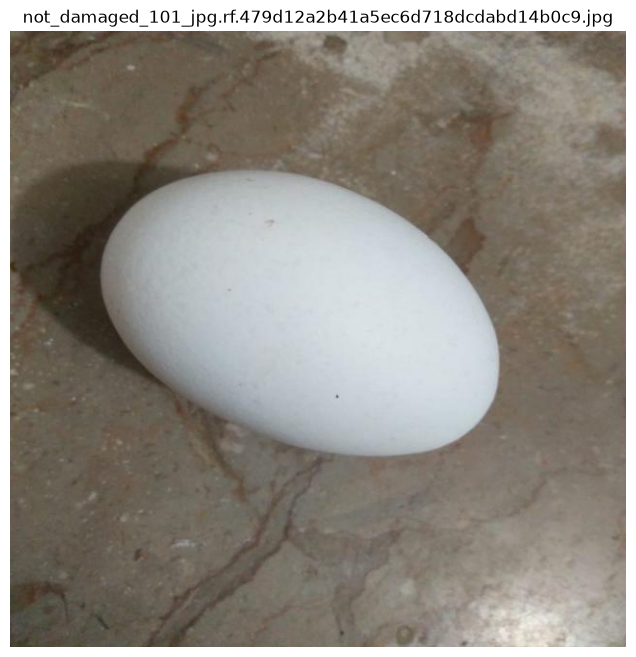

In [66]:
image_path = test_dir / "not_damaged_101_jpg.rf.479d12a2b41a5ec6d718dcdabd14b0c9.jpg"

image_bgr = cv2.imread(str(image_path))
image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.title(image_path.name)
plt.axis("off")
plt.show()

In [67]:
inputs = processor_dino(
    images=image,
    text="egg.",
    return_tensors="pt"
)

start_time = time.perf_counter()

with torch.no_grad():
    outputs = model_dino(**inputs)

results = processor_dino.post_process_grounded_object_detection(
    outputs,
    inputs.input_ids,
    threshold=0.25,
    text_threshold=0.25,
    target_sizes=[image.shape[:2]]
)[0]

boxes = results["boxes"].cpu().numpy()
scores = results["scores"].cpu().numpy()
labels = results["labels"]

print("Eggs detected:", len(boxes))
print(f"DINO inference time: {time.perf_counter() - start_time:.2f} seconds")

for label, score in zip(labels, scores):
    print(f"{label}: {score:.3f}")

Eggs detected: 1
DINO inference time: 5.75 seconds
egg: 0.946


In [68]:
predictor.set_image(image)

start_time = time.perf_counter()
egg_masks = []

for box in boxes:
    masks, sam_scores, _ = predictor.predict(
        box=box.astype(np.float32),
        multimask_output=False
    )
    egg_masks.append(masks[0])

print("Eggs segmented:", len(egg_masks))
print(f"SAM segmentation time: {time.perf_counter() - start_time:.2f} seconds")

Eggs segmented: 1
SAM segmentation time: 0.06 seconds


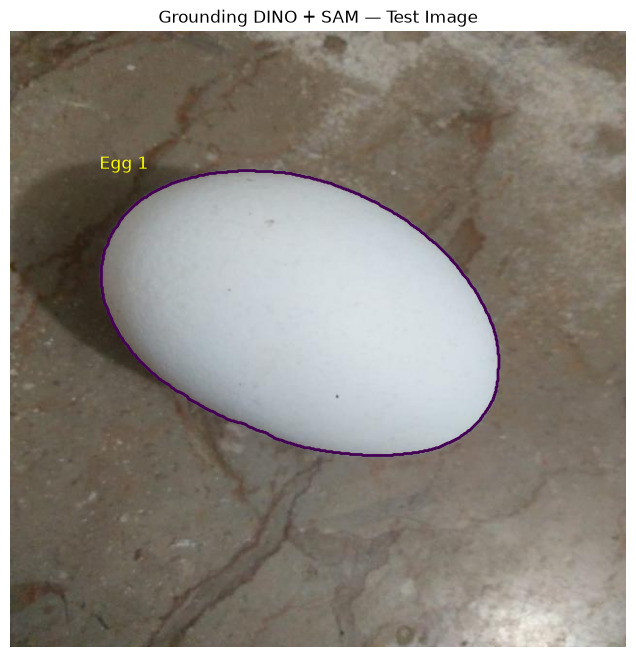

In [69]:
plt.figure(figsize=(10, 8))
plt.imshow(image)

ax = plt.gca()

for i, mask in enumerate(egg_masks):
    ax.contour(mask.astype(float), levels=[0.5], linewidths=2)
    x1, y1, _, _ = boxes[i]
    ax.text(x1, y1, f"Egg {i+1}", color="yellow", fontsize=12)

plt.title("Grounding DINO + SAM — Test Image")
plt.axis("off")
plt.show()

## Test on few more images 

In [73]:

test_dir = Path("data/test/egg")
test_images = sorted(test_dir.glob("*.jpg"))

# Select three images we haven't tested yet
selected_images = test_images[1:4]

for path in selected_images:
    print(path.name)

not_damaged_125_jpg.rf.b19353b1f84dcbef1ec088b850927bb3.jpg
not_damaged_14_jpg.rf.dc96559078b03433d2b65e5055904af1.jpg
not_damaged_152_jpg.rf.a57edb18d395ce87e23f7abccbd1ad69.jpg


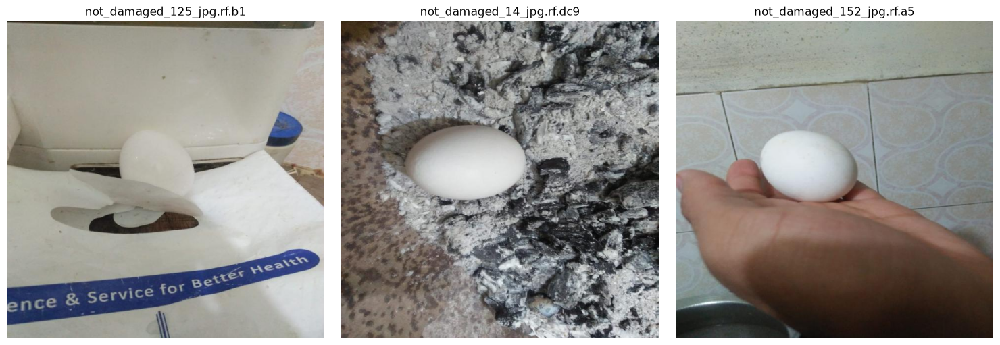

In [74]:


fig, axes = plt.subplots(1, len(selected_images), figsize=(15, 5))

for ax, path in zip(axes, selected_images):
    img_bgr = cv2.imread(str(path))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    ax.imshow(img_rgb)
    ax.set_title(path.name[:25])
    ax.axis("off")

plt.tight_layout()
plt.show()

not_damaged_125_jpg.rf.b19353b1f84dcbef1ec088b850927bb3.jpg: 2 eggs detected | 5.26s


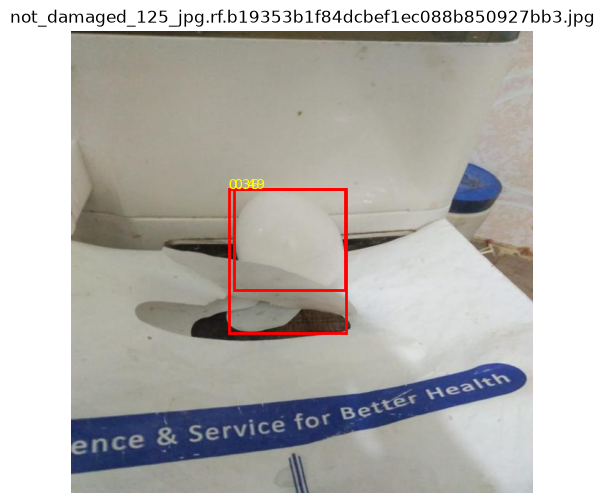

not_damaged_14_jpg.rf.dc96559078b03433d2b65e5055904af1.jpg: 1 eggs detected | 5.42s


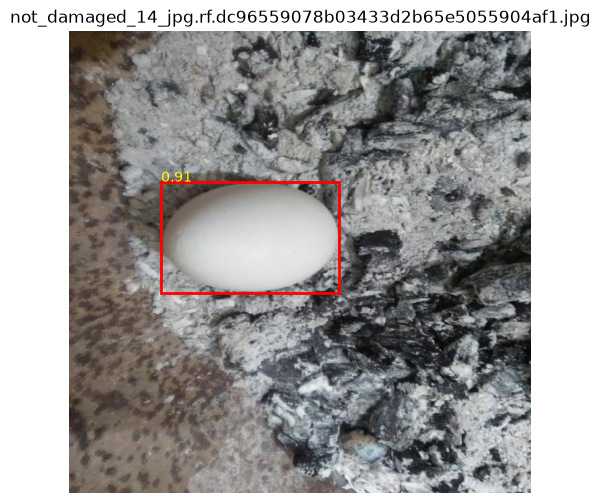

not_damaged_152_jpg.rf.a57edb18d395ce87e23f7abccbd1ad69.jpg: 1 eggs detected | 5.63s


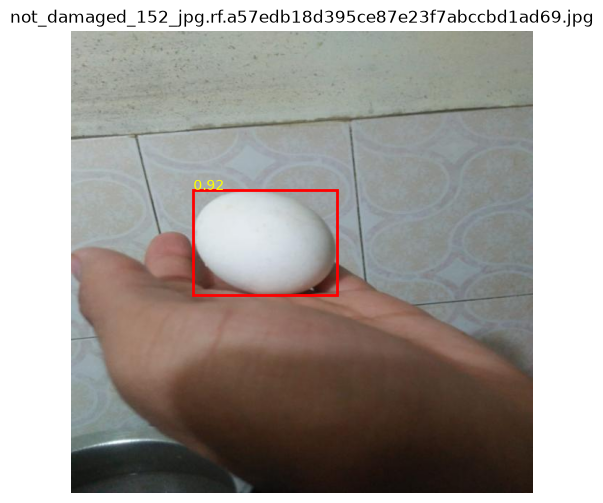

In [76]:
import matplotlib.patches as patches

dino_results = []

for path in selected_images:
    img_bgr = cv2.imread(str(path))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    inputs = processor_dino(
        images=img_rgb,
        text="egg.",
        return_tensors="pt"
    )

    start = time.perf_counter()

    with torch.no_grad():
        outputs = model_dino(**inputs)

    detections = processor_dino.post_process_grounded_object_detection(
        outputs,
        inputs.input_ids,
        threshold=0.25,
        text_threshold=0.25,
        target_sizes=[img_rgb.shape[:2]]
    )[0]

    elapsed = time.perf_counter() - start
    boxes = detections["boxes"].cpu().numpy()
    scores = detections["scores"].cpu().numpy()

    dino_results.append({
        "path": path,
        "image": img_rgb,
        "boxes": boxes,
        "scores": scores,
        "dino_time": elapsed
    })

    print(f"{path.name}: {len(boxes)} eggs detected | {elapsed:.2f}s")

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(img_rgb)

    for box, score in zip(boxes, scores):
        x1, y1, x2, y2 = box
        ax.add_patch(
            patches.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                linewidth=2, edgecolor="red", facecolor="none"
            )
        )
        ax.text(x1, y1, f"{score:.2f}", color="yellow")

    ax.set_title(path.name)
    ax.axis("off")
    plt.show()

In [77]:
# Generate segmentation masks
for result in dino_results:
    predictor.set_image(result["image"])

    start = time.perf_counter()
    masks_list = []

    for box in result["boxes"]:
        masks, sam_scores, _ = predictor.predict(
            box=box.astype(np.float32),
            multimask_output=False
        )
        masks_list.append(masks[0])

    result["masks"] = masks_list
    result["sam_time"] = time.perf_counter() - start

    print(
        f"{result['path'].name}: "
        f"{len(masks_list)} masks generated | "
        f"SAM time: {result['sam_time']:.2f}s"
    )

not_damaged_125_jpg.rf.b19353b1f84dcbef1ec088b850927bb3.jpg: 2 masks generated | SAM time: 0.13s
not_damaged_14_jpg.rf.dc96559078b03433d2b65e5055904af1.jpg: 1 masks generated | SAM time: 0.06s
not_damaged_152_jpg.rf.a57edb18d395ce87e23f7abccbd1ad69.jpg: 1 masks generated | SAM time: 0.07s


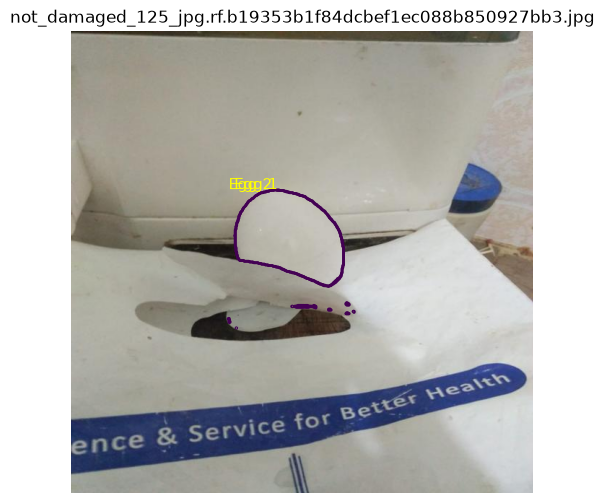

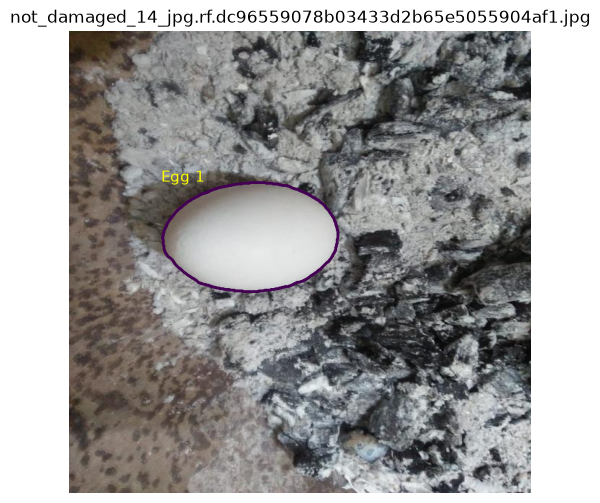

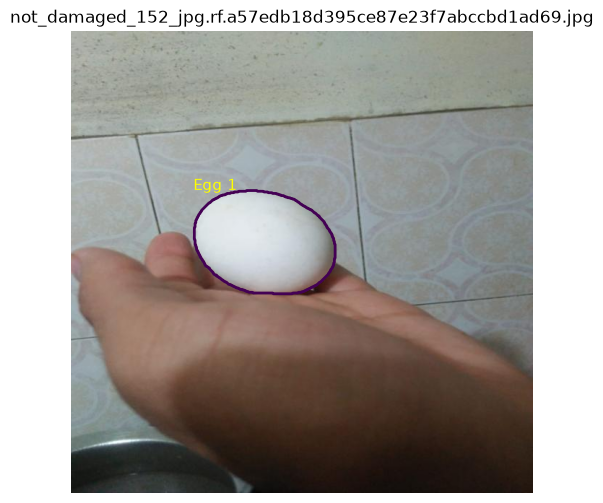

In [78]:

for result in dino_results:
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(result["image"])

    for i, mask in enumerate(result["masks"]):
        ax.contour(
            mask.astype(float),
            levels=[0.5],
            linewidths=2
        )

        x1, y1, _, _ = result["boxes"][i]
        ax.text(x1, y1, f"Egg {i+1}", color="yellow", fontsize=11)

    ax.set_title(result["path"].name)
    ax.axis("off")
    plt.show()

## Conclusion

In this notebook, I experimented with different approaches for egg segmentation.

- **SAM Automatic Mask Generation:** Generated multiple candidate masks, including irrelevant, overlapping, and partial regions. Selecting the correct egg masks would require additional filtering.
- **Classical Image Processing:** Tried Otsu thresholding, connected components, local intensity maxima, and edge detection. These approaches struggled to separate eggs from the background reliably.
- **Grounding DINO + SAM:** Grounding DINO detected eggs using the text prompt `"egg."`, and SAM generated individual segmentation masks using the detected bounding boxes.

### Final Observation

Grounding DINO + SAM produced visually accurate egg boundaries on the five images tested. The detection and segmentation results were promising, so I selected this combination for the next stage of development.

Both models were run on the CPU during these experiments because of the available GPU memory constraints.

### Next Steps

Build a reusable Python pipeline combining Grounding DINO and SAM.

Run the pipeline on all available dataset images.

Save individual egg masks and handle detection or segmentation failures.

Evaluate segmentation quality quantitatively using ground-truth masks and metrics such as IoU and Dice score.